# SmartWafer — Classification Training (versi diperbaiki)

Target: `defect_label` (0 = Tidak Defect, 1 = Defect). Data: 5.000 baris, **hanya 7 defect (0,14%)**.

## Apa yang diperbaiki dari notebook sebelumnya

| Masalah di versi lama | Perbaikan di notebook ini |
|---|---|
| Test set 1.000 baris hanya berisi **1 defect**. SVM "F1 = 1.0" itu hasil menebak 1 sampel dengan benar, bukan bukti model bagus. Model lain gagal pada 1 sampel yang sama. | Evaluasi memakai **Repeated Stratified 5-Fold CV (10 ulangan)** sehingga ke-7 defect semuanya dinilai sebagai data *out-of-fold*. |
| Accuracy / F1 pada threshold 0,5 sebagai penentu model. | Metrik utama **PR-AUC (Average Precision)**, ROC-AUC, dan **Recall pada anggaran alert 1% / 5%**. Semuanya tidak bergantung pada threshold 0,5. |
| Hanya `class_weight="balanced"`. | Dibandingkan: class weight, **SMOTE di dalam pipeline** (tidak bocor ke validasi), **Balanced Random Forest**, dan **Isolation Forest** (pendekatan anomaly). |
| Threshold default 0,5 untuk model yang disimpan. | **Threshold dipilih dari skor out-of-fold** (maksimalkan F2, recall lebih diutamakan) dan disimpan bersama model. |
| `import preprocessing` tidak ada di notebook lama (cell memakai `preprocessing.load_data` tanpa import). | Ditambahkan. |
| Tidak ada pembanding. | Ada **baseline acak** (AP ≈ prevalensi) dan **cek sinyal per fitur** untuk memastikan defect memang bisa dibedakan. |

> **Catatan jujur:** dengan 7 sampel defect, tidak ada teknik yang bisa menjamin akurasi tinggi. Yang bisa dilakukan adalah memilih model dengan cara yang benar dan memberi angka performa yang jujur (rata-rata ± standar deviasi antar ulangan). Peningkatan sebenarnya hanya datang dari **lebih banyak data defect**.

## 1. Import library

In [14]:
import os, sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, IsolationForest
from sklearn.svm import SVC
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_recall_curve
)

# imbalanced-learn dipakai untuk SMOTE dan Balanced Random Forest.
# Instal bila belum ada:  pip install imbalanced-learn
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE
    from imblearn.ensemble import BalancedRandomForestClassifier
    HAS_IMBLEARN = True
except ImportError:
    HAS_IMBLEARN = False
    print("imbalanced-learn belum terpasang -> model SMOTE dan Balanced RF dilewati. "
          "Instal dengan: pip install imbalanced-learn")

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
N_SPLITS = 5
N_REPEATS = 10
print("scikit-learn:", sklearn.__version__, "| imblearn:", HAS_IMBLEARN)

scikit-learn: 1.9.1 | imblearn: True


## 2. Lokasi proyek, `preprocessing.py`, dan dataset

In [15]:
CURRENT_DIR = Path.cwd().resolve()
possible_roots = [CURRENT_DIR, CURRENT_DIR.parent]

PROJECT_ROOT = next(
    (p for p in possible_roots if (p / "preprocessing.py").exists()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "preprocessing.py tidak ditemukan. Jalankan notebook dari folder proyek "
        "atau sesuaikan PROJECT_ROOT secara manual."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import preprocessing

candidate_paths = [
    PROJECT_ROOT / "data" / "processed" / "semiconductor_wafer_defect_featured.csv",
    PROJECT_ROOT / "data" / "processed" / "semiconductor_wafer_defect_clean.csv",
    PROJECT_ROOT / "data" / "raw" / "semiconductor_wafer_defect_dataset.csv",
]

DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset CSV tidak ditemukan. Periksa candidate_paths pada cell ini."
    )

print("Project root:", PROJECT_ROOT)
print("Dataset:", DATA_PATH)

Project root: D:\mq\kuliah\semester5\Project Machine Learning\SmartWafer- Aplikasi Web Terintegrasi untuk Klasifikasi Defect dan Clustering Kondisi Wafer
Dataset: D:\mq\kuliah\semester5\Project Machine Learning\SmartWafer- Aplikasi Web Terintegrasi untuk Klasifikasi Defect dan Clustering Kondisi Wafer\data\processed\semiconductor_wafer_defect_featured.csv


## 3. Muat data

`preprocessing.py` tidak diubah, jadi backend FastAPI tetap memakai fungsi yang sama. Imputasi dan scaling tetap berada di dalam pipeline model agar parameternya hanya dipelajari dari data training tiap fold.

In [16]:
df = preprocessing.load_data(DATA_PATH)
df = preprocessing.feature_engineering(df)
df = df.dropna(subset=["defect_label"]).copy()
df["defect_label"] = df["defect_label"].astype(int)

X, y = preprocessing.split_features_target(df)
X = X.reset_index(drop=True)
y = y.reset_index(drop=True)

n_pos = int(y.sum())
prevalence = y.mean()
print("X:", X.shape, "| defect:", n_pos, f"| prevalensi: {prevalence:.4%}")
assert n_pos >= N_SPLITS, "Jumlah defect lebih kecil dari jumlah fold; kurangi N_SPLITS."

X: (5000, 8) | defect: 7 | prevalensi: 0.1400%


## 4. Cek sinyal: apakah defect memang bisa dibedakan?

Sebelum memilih model, cek seberapa baik **tiap fitur sendirian** memisahkan defect (Average Precision). Pembandingnya adalah prevalensi (≈ 0,0014): skor acak menghasilkan AP sebesar itu. Bila tidak ada fitur yang jauh di atasnya, masalahnya ada di data, bukan di algoritma.

In [17]:
num_cols = X.select_dtypes(include="number").columns.tolist()
rows = []
for c in num_cols:
    s = X[c]
    rows.append({
        "fitur": c,
        "AP_nilai_tinggi": average_precision_score(y, s),
        "AP_nilai_rendah": average_precision_score(y, -s),
        "AP_menyimpang_dari_median": average_precision_score(y, (s - s.median()).abs()),
        "z_rata2_defect": (s[y == 1].mean() - s.mean()) / s.std(),
    })
signal = pd.DataFrame(rows).set_index("fitur")
signal["AP_terbaik"] = signal[["AP_nilai_tinggi", "AP_nilai_rendah", "AP_menyimpang_dari_median"]].max(axis=1)
print(f"Baseline acak (AP) = prevalensi = {prevalence:.4f}")
display(signal.sort_values("AP_terbaik", ascending=False).round(4))

print("\nProses (process_step) pada sampel defect:")
display(X.loc[y == 1, "process_step"].value_counts().to_frame("jumlah_defect"))

Baseline acak (AP) = prevalensi = 0.0014


,AP_nilai_tinggi,AP_nilai_rendah,AP_menyimpang_dari_median,z_rata2_defect,AP_terbaik
fitur,,,,,
etch_rate_nm_min,0.1689,0.0011,0.1549,1.3791,0.1689
pressure_torr,0.0008,0.0725,0.0354,-2.2955,0.0725
temperature_c,0.0516,0.0011,0.0283,1.3650,0.0516
electrical_power_mw,0.0035,0.0012,0.0021,0.4870,0.0035
voltage_v,0.0026,0.0012,0.0015,0.4348,0.0026
gas_flow_sccm,0.0012,0.0021,0.0014,-0.3013,0.0021
current_ma,0.0020,0.0013,0.0011,0.2511,0.0020



Proses (process_step) pada sampel defect:


,jumlah_defect
process_step,
Lithography,2
Oxidation,2
CMP,2
Etching,1


## 5. Pipeline preprocessing

In [18]:
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
])
print("Numerik:", numeric_features)
print("Kategorikal:", categorical_features)

Numerik: ['temperature_c', 'pressure_torr', 'gas_flow_sccm', 'etch_rate_nm_min', 'voltage_v', 'current_ma', 'electrical_power_mw']
Kategorikal: ['process_step']


## 6. Definisi model

Strategi imbalance yang dibandingkan:

- **Class weight**: Logistic Regression, Random Forest (`balanced_subsample`), Extra Trees, SVM.
- **SMOTE di dalam pipeline**: oversampling hanya terjadi pada data training tiap fold. `k_neighbors=3` karena tiap fold training hanya punya 5–6 defect.
- **Balanced Random Forest**: tiap pohon dilatih pada sampel yang diseimbangkan lewat undersampling kelas mayoritas.
- **Isolation Forest**: tanpa label (anomaly detection); defect diperlakukan sebagai kasus langka yang menyimpang. Berguna bila defect tidak punya pola yang konsisten.

Hyperparameter sengaja dibuat konservatif (regularisasi kuat, `min_samples_leaf` > 1) agar tidak menghafal 5–6 sampel defect.

In [19]:
class IsolationScorer(BaseEstimator, ClassifierMixin):
    """Pembungkus IsolationForest agar bisa dipakai di Pipeline. Skor tinggi = lebih anomali."""
    def __init__(self, n_estimators=500, random_state=RANDOM_STATE):
        self.n_estimators = n_estimators
        self.random_state = random_state

    def fit(self, X, y=None):
        self.model_ = IsolationForest(
            n_estimators=self.n_estimators, random_state=self.random_state, n_jobs=-1
        ).fit(X)
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        s = -self.model_.score_samples(X)
        return np.column_stack([-s, s])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] > 0).astype(int)  # tidak dipakai; threshold dipilih terpisah


def make_pipe(clf):
    return Pipeline([("prep", clone(preprocessor)), ("clf", clf)])

pipelines = {
    "LogReg (balanced, C=0.1)": make_pipe(LogisticRegression(
        C=0.1, class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE)),
    "LogReg (balanced, C=1)": make_pipe(LogisticRegression(
        C=1.0, class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE)),
    "Random Forest (balanced_subsample)": make_pipe(RandomForestClassifier(
        n_estimators=500, class_weight="balanced_subsample", min_samples_leaf=3,
        random_state=RANDOM_STATE, n_jobs=-1)),
    "Extra Trees (balanced_subsample)": make_pipe(ExtraTreesClassifier(
        n_estimators=500, class_weight="balanced_subsample", min_samples_leaf=3,
        random_state=RANDOM_STATE, n_jobs=-1)),
    "SVM RBF (balanced)": make_pipe(SVC(
        kernel="rbf", C=1.0, class_weight="balanced")),     # skor = decision_function
    "Isolation Forest (anomaly)": make_pipe(IsolationScorer()),
}

if HAS_IMBLEARN:
    def make_smote_pipe(clf):
        return ImbPipeline([
            ("prep", clone(preprocessor)),
            ("smote", SMOTE(sampling_strategy=0.1, k_neighbors=3, random_state=RANDOM_STATE)),
            ("clf", clf),
        ])
    pipelines["LogReg + SMOTE"] = make_smote_pipe(LogisticRegression(
        C=0.1, max_iter=5000, random_state=RANDOM_STATE))
    pipelines["Random Forest + SMOTE"] = make_smote_pipe(RandomForestClassifier(
        n_estimators=500, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1))
    pipelines["Balanced Random Forest"] = make_pipe(BalancedRandomForestClassifier(
        n_estimators=500, sampling_strategy="all", replacement=True, bootstrap=False,
        min_samples_leaf=1, random_state=RANDOM_STATE, n_jobs=-1))

print(len(pipelines), "model:", list(pipelines))

9 model: ['LogReg (balanced, C=0.1)', 'LogReg (balanced, C=1)', 'Random Forest (balanced_subsample)', 'Extra Trees (balanced_subsample)', 'SVM RBF (balanced)', 'Isolation Forest (anomaly)', 'LogReg + SMOTE', 'Random Forest + SMOTE', 'Balanced Random Forest']


## 7. Evaluasi: Repeated Stratified K-Fold dengan skor out-of-fold

Untuk tiap ulangan, setiap baris dinilai oleh model yang **tidak pernah melihatnya** saat training. Skor dari 5 fold digabung, lalu metrik dihitung pada seluruh 5.000 baris (termasuk ke-7 defect). Hasil akhirnya adalah rata-rata ± standar deviasi dari 10 ulangan.

- **Average Precision (PR-AUC)**: metrik utama untuk data sangat imbalance. Skor acak ≈ prevalensi.
- **Recall@1% / Recall@5%**: bila hanya 1% (50 wafer) atau 5% (250 wafer) dengan skor tertinggi yang diperiksa manual, berapa porsi defect yang tertangkap? Acak ≈ 1% / 5%.

In [20]:
def get_scores(model, X_val):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_val)[:, 1]
    return model.decision_function(X_val)

def recall_at_budget(y_true, scores, frac):
    k = int(np.ceil(frac * len(y_true)))
    top = np.argsort(-scores, kind="stable")[:k]
    return y_true[top].sum() / y_true.sum()

y_arr = y.to_numpy()
rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE)
splits = list(rskf.split(X, y))

oof_scores = {}      # nama model -> array (N_REPEATS, n_sampel)
per_repeat = {}      # nama model -> DataFrame metrik per ulangan

for name, pipe in pipelines.items():
    print(f"Evaluasi: {name}")
    try:
        oof = np.zeros((N_REPEATS, len(y)))
        for i, (tr, va) in enumerate(splits):
            m = clone(pipe).fit(X.iloc[tr], y.iloc[tr])
            oof[i // N_SPLITS, va] = get_scores(m, X.iloc[va])
    except Exception as e:
        print(f"   DILEWATI ({type(e).__name__}: {e})")
        continue

    oof_scores[name] = oof
    per_repeat[name] = pd.DataFrame({
        "AP": [average_precision_score(y_arr, oof[r]) for r in range(N_REPEATS)],
        "ROC_AUC": [roc_auc_score(y_arr, oof[r]) for r in range(N_REPEATS)],
        "Recall@1%": [recall_at_budget(y_arr, oof[r], 0.01) for r in range(N_REPEATS)],
        "Recall@5%": [recall_at_budget(y_arr, oof[r], 0.05) for r in range(N_REPEATS)],
    })

summary = pd.concat(
    {n: pd.concat([d.mean().add_suffix("_mean"), d.std().add_suffix("_std")]) for n, d in per_repeat.items()},
    axis=1
).T
summary = summary[["AP_mean", "AP_std", "ROC_AUC_mean", "ROC_AUC_std",
                   "Recall@1%_mean", "Recall@1%_std", "Recall@5%_mean", "Recall@5%_std"]]
summary = summary.sort_values(["AP_mean", "Recall@1%_mean"], ascending=False)

print(f"\nReferensi acak: AP = {prevalence:.4f} | ROC_AUC = 0.5 | Recall@1% = 0.01 | Recall@5% = 0.05")
display(summary.round(3))

Evaluasi: LogReg (balanced, C=0.1)
Evaluasi: LogReg (balanced, C=1)
Evaluasi: Random Forest (balanced_subsample)
Evaluasi: Extra Trees (balanced_subsample)
Evaluasi: SVM RBF (balanced)
Evaluasi: Isolation Forest (anomaly)
Evaluasi: LogReg + SMOTE
Evaluasi: Random Forest + SMOTE
Evaluasi: Balanced Random Forest

Referensi acak: AP = 0.0014 | ROC_AUC = 0.5 | Recall@1% = 0.01 | Recall@5% = 0.05


,AP_mean,AP_std,ROC_AUC_mean,ROC_AUC_std,Recall@1%_mean,Recall@1%_std,Recall@5%_mean,Recall@5%_std
SVM RBF (balanced),0.382,0.064,0.977,0.025,0.800,0.074,0.943,0.074
"LogReg (balanced, C=0.1)",0.345,0.036,0.986,0.011,0.786,0.168,0.886,0.148
"LogReg (balanced, C=1)",0.340,0.035,0.985,0.011,0.643,0.181,0.886,0.148
LogReg + SMOTE,0.316,0.028,0.984,0.012,0.686,0.113,0.886,0.148
Balanced Random Forest,0.173,0.057,0.990,0.004,0.657,0.120,0.943,0.074
Random Forest + SMOTE,0.159,0.058,0.992,0.002,0.729,0.081,1.000,0.000
Random Forest (balanced_subsample),0.143,0.046,0.978,0.027,0.671,0.069,0.914,0.120
Extra Trees (balanced_subsample),0.097,0.060,0.880,0.116,0.357,0.226,0.614,0.294
Isolation Forest (anomaly),0.015,0.002,0.904,0.009,0.143,0.000,0.200,0.074


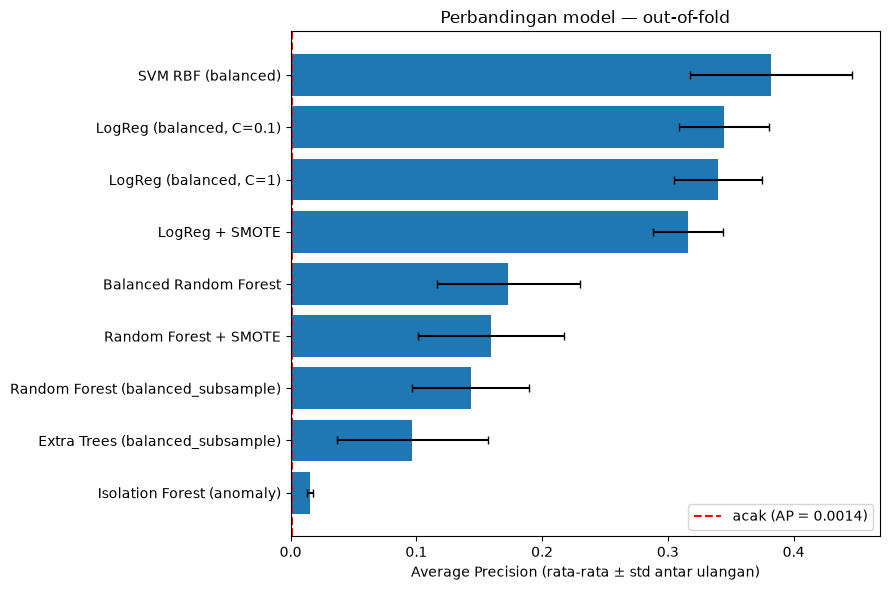

In [21]:
fig, ax = plt.subplots(figsize=(9, 0.5 * len(summary) + 1.5))
order = summary.index[::-1]
ax.barh(order, summary.loc[order, "AP_mean"], xerr=summary.loc[order, "AP_std"], capsize=3)
ax.axvline(prevalence, color="red", ls="--", label=f"acak (AP = {prevalence:.4f})")
ax.set_xlabel("Average Precision (rata-rata ± std antar ulangan)")
ax.set_title("Perbandingan model — out-of-fold")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Pilih model dan tentukan threshold

Model dipilih berdasarkan **Average Precision rata-rata** (tie-breaker: Recall@1%). Threshold dipilih dari skor out-of-fold dengan memaksimalkan **F2** (recall dibobotkan lebih besar daripada precision, karena melewatkan defect umumnya lebih mahal daripada false alarm). Sesuaikan `BETA` dengan kebutuhan pabrik.

> Jika model terbaik tidak jauh di atas baseline acak, **jangan dipakai untuk keputusan produksi**. Hasil tabel di atas menunjukkan itu.

Model terpilih: SVM RBF (balanced)


,AP_mean,AP_std,ROC_AUC_mean,ROC_AUC_std,Recall@1%_mean,Recall@1%_std,Recall@5%_mean,Recall@5%_std
SVM RBF (balanced),0.382,0.064,0.977,0.025,0.8,0.074,0.943,0.074



Threshold terpilih: -0.3431  (F2 OOF = 0.468)
Rata-rata per satu kali evaluasi penuh: TP=3.6  FN=3.4  FP=6.9  TN=4986.1
Recall = 0.514 | Precision = 0.343
Catatan: threshold dipilih pada data yang sama dengan penilaiannya, jadi angka ini sedikit optimistis.


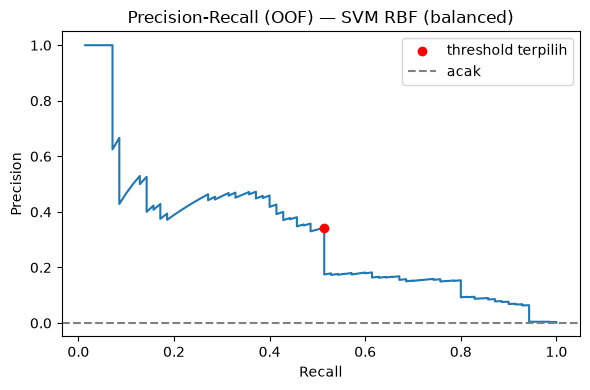

In [22]:
BETA = 2.0

best_name = summary.index[0]
print("Model terpilih:", best_name)
display(summary.loc[[best_name]].round(3))

# Gabungkan skor out-of-fold seluruh ulangan untuk memilih threshold
scores_all = oof_scores[best_name].ravel()
y_all = np.tile(y_arr, N_REPEATS)

prec, rec, thr = precision_recall_curve(y_all, scores_all)
prec, rec = prec[:-1], rec[:-1]
fbeta = (1 + BETA**2) * prec * rec / np.clip(BETA**2 * prec + rec, 1e-12, None)
best_idx = int(np.nanargmax(fbeta))
threshold = float(thr[best_idx])

pred_all = (scores_all >= threshold).astype(int)
tp = int(((pred_all == 1) & (y_all == 1)).sum()) / N_REPEATS
fn = int(((pred_all == 0) & (y_all == 1)).sum()) / N_REPEATS
fp = int(((pred_all == 1) & (y_all == 0)).sum()) / N_REPEATS
tn = int(((pred_all == 0) & (y_all == 0)).sum()) / N_REPEATS

print(f"\nThreshold terpilih: {threshold:.4f}  (F{BETA:g} OOF = {fbeta[best_idx]:.3f})")
print(f"Rata-rata per satu kali evaluasi penuh: TP={tp:.1f}  FN={fn:.1f}  FP={fp:.1f}  TN={tn:.1f}")
print(f"Recall = {tp / (tp + fn):.3f} | Precision = {tp / max(tp + fp, 1e-9):.3f}")
print("Catatan: threshold dipilih pada data yang sama dengan penilaiannya, jadi angka ini sedikit optimistis.")

plt.figure(figsize=(6, 4))
plt.plot(rec, prec)
plt.scatter([rec[best_idx]], [prec[best_idx]], color="red", zorder=3, label="threshold terpilih")
plt.axhline(prevalence, color="gray", ls="--", label="acak")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title(f"Precision-Recall (OOF) — {best_name}")
plt.legend(); plt.tight_layout(); plt.show()

## 9. Latih ulang pada seluruh data dan simpan artefak

Setelah model dipilih lewat CV, model dilatih ulang pada **semua** data (jangan membuang sebagian defect yang sangat berharga untuk test set).

In [23]:
final_model = clone(pipelines[best_name]).fit(X, y)

MODEL_DIR = PROJECT_ROOT / "models" / "classification"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(final_model, MODEL_DIR / "best_model.joblib")
summary.round(4).to_csv(MODEL_DIR / "model_comparison.csv")

metadata = {
    "project": "SmartWafer",
    "target_column": "defect_label",
    "class_mapping": {"0": "Tidak Defect", "1": "Defect"},
    "selected_model": best_name,
    "decision_threshold": threshold,
    "threshold_rule": f"maksimalkan F{BETA:g} pada skor out-of-fold",
    "score_type": "predict_proba[:, 1]" if hasattr(final_model, "predict_proba") else "decision_function",
    "cv": f"RepeatedStratifiedKFold({N_SPLITS} fold x {N_REPEATS} ulangan)",
    "cv_metrics": {k: round(float(v), 4) for k, v in summary.loc[best_name].items()},
    "feature_columns": X.columns.tolist(),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "n_defect_samples": n_pos,
    "n_samples": int(len(y)),
    "random_state": RANDOM_STATE,
    "sklearn_version": sklearn.__version__,
    "warning": ("Hanya %d sampel defect dari %d baris. Performa sangat tidak pasti; "
                "validasi dengan lebih banyak data defect sebelum produksi." % (n_pos, len(y))),
}
with open(MODEL_DIR / "model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print("Tersimpan di:", MODEL_DIR)

Tersimpan di: D:\mq\kuliah\semester5\Project Machine Learning\SmartWafer- Aplikasi Web Terintegrasi untuk Klasifikasi Defect dan Clustering Kondisi Wafer\models\classification


SVM RBF (balanced) tidak punya importance bawaan; lihat bagian B.


,penurunan_AP_mean,std_antar_fold
pressure_torr,0.4344,0.4046
temperature_c,0.3407,0.4164
etch_rate_nm_min,0.0955,0.0772
gas_flow_sccm,0.0736,0.1857
current_ma,0.0373,0.0833
process_step,-0.0134,0.1311
voltage_v,-0.0247,0.1648
electrical_power_mw,-0.0316,0.1445


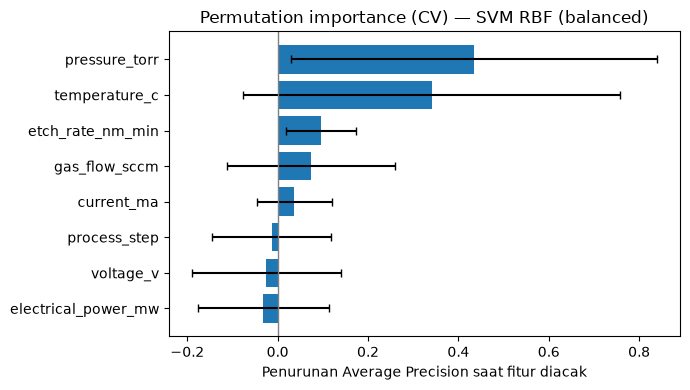

In [25]:
# ===== Feature importance =====

# --- A. Importance bawaan model (hanya ada pada RF, ExtraTrees, BalancedRF, LogReg) ---
prep = final_model.named_steps["prep"]
clf = final_model.named_steps["clf"]
feat_names = prep.get_feature_names_out()

if hasattr(clf, "feature_importances_"):
    raw_imp = clf.feature_importances_
elif hasattr(clf, "coef_"):
    raw_imp = np.abs(clf.coef_.ravel())      # fitur sudah di-scale, jadi koefisien bisa dibandingkan
else:
    raw_imp = None

if raw_imp is not None:
    # gabungkan hasil one-hot (process_step_*) kembali ke fitur asalnya
    agg = {}
    for name, v in zip(feat_names, raw_imp):
        base = name.split("__", 1)[1]
        for c in categorical_features:
            if base.startswith(c + "_"):
                base = c
        agg[base] = agg.get(base, 0) + v
    model_imp = pd.Series(agg).sort_values(ascending=False)
    print("Importance bawaan model:")
    display(model_imp.to_frame("importance").round(4))
else:
    print(f"{best_name} tidak punya importance bawaan; lihat bagian B.")

# --- B. Permutation importance di dalam CV (lebih jujur, berlaku untuk semua model) ---
# Penurunan Average Precision pada data validasi saat satu fitur diacak.
# Dipakai 3 ulangan CV pertama agar tidak terlalu lama; naikkan bila perlu.
N_PERM = 5
rng = np.random.default_rng(RANDOM_STATE)
perm = {c: [] for c in X.columns}

for tr, va in splits[: 3 * N_SPLITS]:
    m = clone(pipelines[best_name]).fit(X.iloc[tr], y.iloc[tr])
    Xv, yv = X.iloc[va], y.iloc[va]
    base_ap = average_precision_score(yv, get_scores(m, Xv))
    for c in X.columns:
        drops = []
        for _ in range(N_PERM):
            Xp = Xv.copy()
            Xp[c] = rng.permutation(Xp[c].values)
            drops.append(base_ap - average_precision_score(yv, get_scores(m, Xp)))
        perm[c].append(np.mean(drops))

perm_df = pd.DataFrame({
    "penurunan_AP_mean": {c: np.mean(v) for c, v in perm.items()},
    "std_antar_fold": {c: np.std(v) for c, v in perm.items()},
}).sort_values("penurunan_AP_mean", ascending=False)
display(perm_df.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
p = perm_df.iloc[::-1]
ax.barh(p.index, p["penurunan_AP_mean"], xerr=p["std_antar_fold"], capsize=3)
ax.axvline(0, color="gray", lw=1)
ax.set_xlabel("Penurunan Average Precision saat fitur diacak")
ax.set_title(f"Permutation importance (CV) — {best_name}")
plt.tight_layout()
plt.show()

## 10. Uji pemuatan model dan fungsi prediksi

Gunakan `predict_defect` yang sama di backend FastAPI: ia memakai **skor + threshold** yang tersimpan, bukan `.predict()` bawaan (yang memakai threshold 0,5 dan hampir selalu menjawab "Tidak Defect" pada data seimbang-tidak).

In [24]:
loaded_model = joblib.load(MODEL_DIR / "best_model.joblib")
with open(MODEL_DIR / "model_metadata.json", encoding="utf-8") as f:
    meta = json.load(f)

def predict_defect(features_df):
    """features_df: kolom sama seperti X (setelah preprocessing.feature_engineering)."""
    feats = features_df[meta["feature_columns"]]
    scores = get_scores(loaded_model, feats)
    return pd.DataFrame({
        "score": scores,
        "defect_pred": (scores >= meta["decision_threshold"]).astype(int),
    }, index=features_df.index)

check = pd.concat([X[y == 1].head(3), X[y == 0].head(3)])
out = predict_defect(check)
out["defect_aktual"] = y.loc[check.index].values
display(out)
print("Catatan: baris defect di atas ikut dipakai saat training akhir, jadi skornya tidak mewakili performa sebenarnya. "
      "Gunakan tabel CV (bagian 7) untuk performa.")

,score,defect_pred,defect_aktual
843,0.999754,1,1
880,1.000163,1,1
973,0.999670,1,1
0,-2.523111,0,0
1,-2.424570,0,0
2,-1.919099,0,0


Catatan: baris defect di atas ikut dipakai saat training akhir, jadi skornya tidak mewakili performa sebenarnya. Gunakan tabel CV (bagian 7) untuk performa.


## 11. Langkah berikutnya yang benar-benar menaikkan akurasi

1. **Tambah data defect**. Ini satu-satunya hal yang berdampak besar. Target praktis: minimal puluhan defect.
2. **Cek apakah label defect konsisten** dan apakah ada fitur yang tidak tercatat (misalnya sensor lain, lot/batch, waktu). Bagian 4 menunjukkan bila fitur saat ini tidak punya sinyal.
3. Jika wafer berasal dari batch/lot yang sama, **gunakan `StratifiedGroupKFold`** agar baris dari batch yang sama tidak terpisah antara training dan validasi.
4. Setelah data defect cukup banyak, baru lakukan **tuning hyperparameter** (nested CV) dan **kalibrasi probabilitas**.